# 仿真星等分布（每个探测器）
统计目录 /home/liyang/ET7/Results/Transit/Simulation_NOdrift/DriftOFF_jit0p36 中所有 .ecsv 文件的星等，并绘制每个探测器的分布。
优先使用 Gaia G Mag（存在则用），否则使用 Kepler Mag。

In [ ]:
from pathlib import Path
from collections import defaultdict
import shlex
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

try:
    from astropy.table import Table
    has_astropy = True
except Exception:
    has_astropy = False

# 指定仿真目录（根据需要可修改）
base_dir = Path.home() / 'ET7' / 'Results' / 'Transit' / 'Simulation_NOdrift' / 'DriftOFF_jit0p36_new' / 'transit_full_01'
files = sorted([p for p in base_dir.rglob('*.ecsv')])
print(f'Found {len(files)} .ecsv files under {base_dir}')

mag_col_candidates = ['Gaia G Mag', 'Kepler Mag', 'Gaia_G_Mag', 'Gmag', 'g_mag', 'mag', 'MAG']
det_col_candidates = ['Detector ID', 'DetectorID', 'Detector', 'detector_id', 'detector']

detector_mags = defaultdict(list)

for f in files:
    print('Reading', f)
    try:
        if has_astropy:
            t = Table.read(str(f), format='ascii.ecsv')
            df = t.to_pandas()
        else:
            # 解析 header（处理带引号的列名），再用 pandas 读取数据
            with open(f, 'r') as fh:
                lines = fh.readlines()
            header_idx = None
            for i, line in enumerate(lines):
                if not line.strip().startswith('#'):
                    header_idx = i
                    break
            if header_idx is None:
                print('No header found in', f)
                continue
            header_line = lines[header_idx].strip()
            cols = shlex.split(header_line)
            df = pd.read_csv(f, sep=r'\s+', header=None, names=cols, comment='#', engine='python')
    except Exception as e:
        print('Failed to read', f, 'error:', e)
        continue
    # 选择星等列
    magcol = next((c for c in mag_col_candidates if c in df.columns), None)
    if magcol is None:
        print('No mag column in', f, 'columns:', list(df.columns)[:20])
        continue
    detcol = next((c for c in det_col_candidates if c in df.columns), None)
    if detcol is None:
        detcol = next((c for c in df.columns if 'Detector' in str(c) or 'detector' in str(c).lower()), None)
    if detcol is None:
        df['Detector ID'] = 'unknown'
        detcol = 'Detector ID'
    # 根据探测器分组收集星等
    for det, sub in df.groupby(detcol):
        submags = pd.to_numeric(sub[magcol], errors='coerce').dropna().values
        if len(submags) > 0:
            detector_mags[str(det)].extend(submags.tolist())

# 转为 numpy 数组
detector_mags = {k: np.array(v) for k, v in detector_mags.items()}
print('Done reading files. Detectors found:', list(detector_mags.keys()))

Found 8 .ecsv files under /home/liyang/ET7/Results/Transit/Simulation_NOdrift/DriftOFF_jit0p36_new/transit_full_01
Reading /home/liyang/ET7/Results/Transit/Simulation_NOdrift/DriftOFF_jit0p36_new/transit_full_01/batch0_ra278.1844_dec37.5704/guide_candidates.ecsv
Reading /home/liyang/ET7/Results/Transit/Simulation_NOdrift/DriftOFF_jit0p36_new/transit_full_01/batch0_ra278.1844_dec37.5704/stars.ecsv
Reading /home/liyang/ET7/Results/Transit/Simulation_NOdrift/DriftOFF_jit0p36_new/transit_full_01/batch1_ra269.5821_dec57.8997/guide_candidates.ecsv
Reading /home/liyang/ET7/Results/Transit/Simulation_NOdrift/DriftOFF_jit0p36_new/transit_full_01/batch1_ra269.5821_dec57.8997/stars.ecsv
Reading /home/liyang/ET7/Results/Transit/Simulation_NOdrift/DriftOFF_jit0p36_new/transit_full_01/batch2_ra310.6239_dec59.2676/guide_candidates.ecsv
Reading /home/liyang/ET7/Results/Transit/Simulation_NOdrift/DriftOFF_jit0p36_new/transit_full_01/batch2_ra310.6239_dec59.2676/stars.ecsv
Reading /home/liyang/ET7/Resul

guide_left: 351 stars
guide_top: 351 stars
guide_right: 351 stars
guide_bottom: 351 stars
Total stars: 1404
Saved figure to /home/liyang/ET7/ET-fsgsim/notebooks/mag_distribution.png


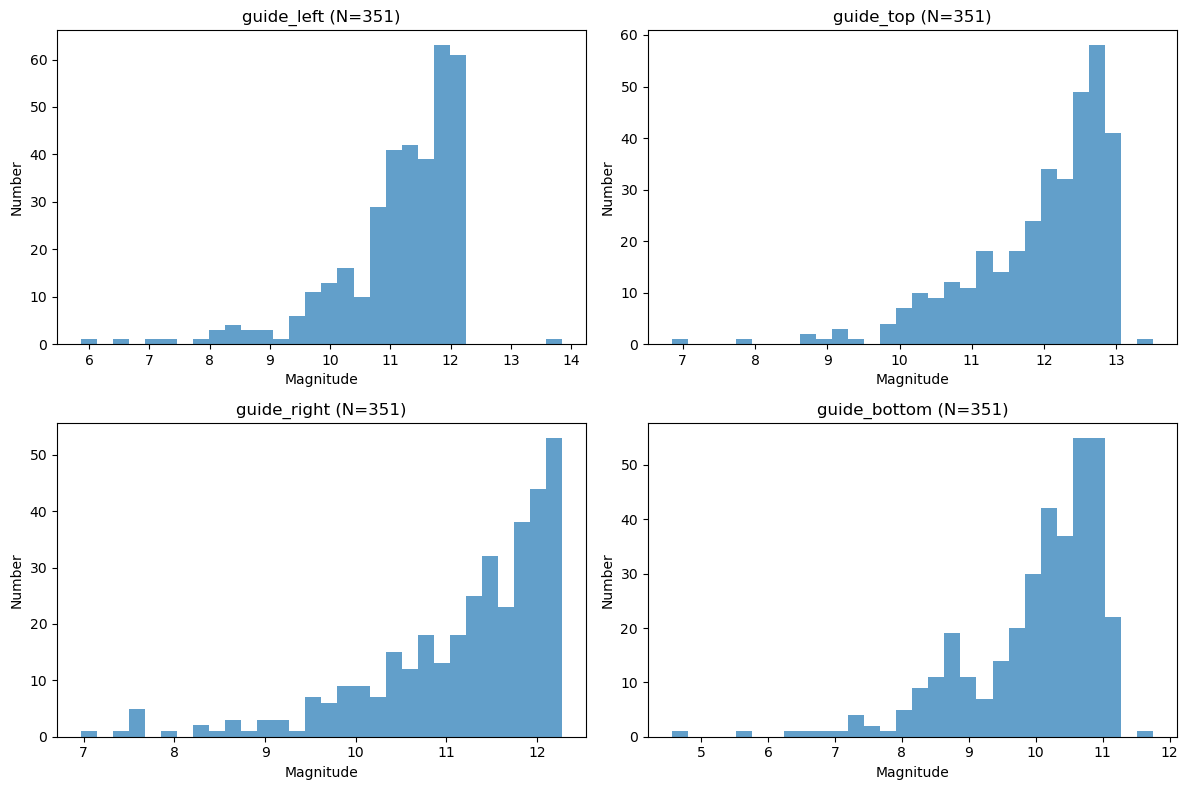

In [ ]:
# 打印每个探测器的仿真星数并绘图
total = 0
for det, arr in detector_mags.items():
    print(f'{det}: {arr.size} stars')
    total += arr.size
print('Total stars:', total)

if len(detector_mags) == 0:
    print('No magnitude data found.')
else:
    detectors = list(detector_mags.keys())
    plot_detectors = detectors[:4] if len(detectors) >= 4 else detectors
    m = len(plot_detectors)
    cols = 2 if m > 1 else 1
    rows = (m + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 4 * rows), squeeze=False)
    axes = axes.flatten()
    for i, det in enumerate(plot_detectors):
        ax = axes[i]
        mags = detector_mags[det]
        ax.hist(mags, bins=30, color='C0', alpha=0.7)
        ax.set_xlabel('Magnitude')
        ax.set_ylabel('Number')
        ax.set_title(f'{det} (N={mags.size})')
    for j in range(m, len(axes)):
        axes[j].axis('off')
    plt.tight_layout()
    out_png = Path.cwd() / 'mag_distribution.png'
    fig.savefig(out_png, dpi=150)
    print('Saved figure to', out_png)
    plt.show()

### 参与解算的星等分布

,detector,selected_count,selected_g_min,selected_g_max,selected_et_min,selected_et_max,saturated_count,saturated_g_max,saturated_et_max
0,guide_left,6000,8.246,11.557,8.361,11.622,0,NaN,NaN
1,guide_top,5906,8.743,12.169,8.850,12.224,0,NaN,NaN
2,guide_right,5860,8.691,12.265,8.799,12.319,0,NaN,NaN
3,guide_bottom,5609,8.249,11.111,8.364,11.182,0,NaN,NaN


Selected attitude stars: 23375
Saturated matched stars: 0
Detected frames: 60


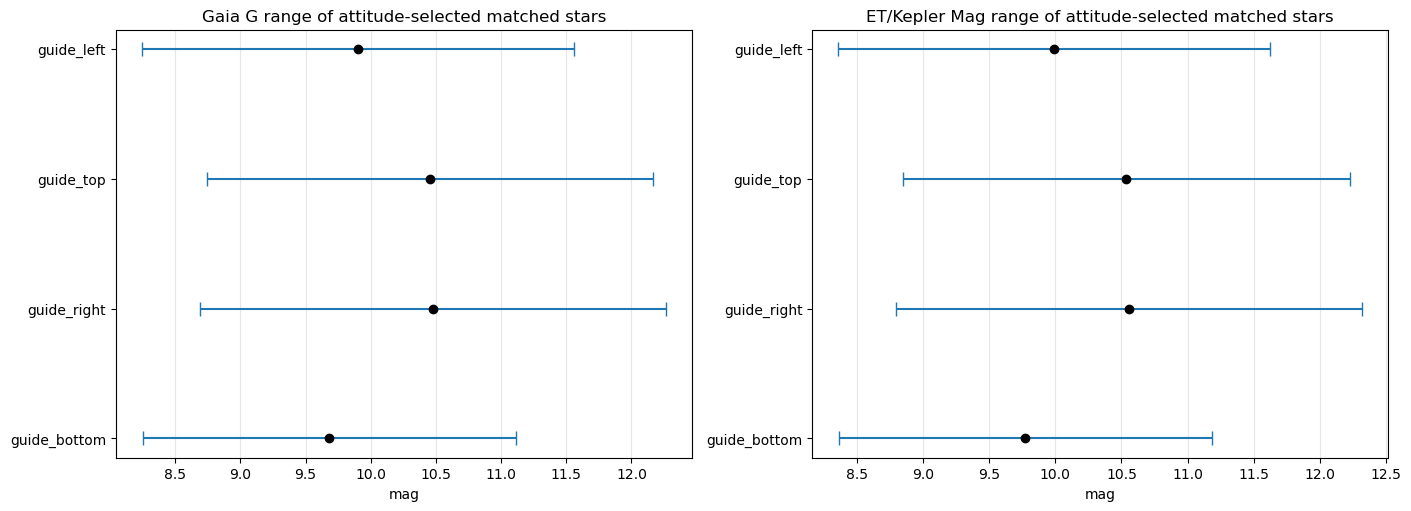

No matched stars reached the saturation threshold in these attitude results.


In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

attitude_root = Path('/home/liyang/ET7/Results/Transit/AttitudeAlgorithm99m/DriftOFF_jit0p36_att_new/transit_att_01/joint_multiframe')
dataset_root = Path('/home/liyang/ET7/Results/Transit/Simulation_NOdrift/DriftOFF_jit0p36_new/transit_full_01')

error_files = sorted(attitude_root.glob('tran_suffix_01_error_audit_joint_f*.json'))
if not error_files:
    raise FileNotFoundError(f'No error_audit JSON files found under {attitude_root}')

try:
    from astropy.table import Table
    use_astropy = True
except Exception:
    use_astropy = False

star_frames = []
for stars_path in sorted(dataset_root.glob('**/stars.ecsv')):
    if use_astropy:
        frame = Table.read(stars_path, format='ascii.ecsv').to_pandas()
    else:
        frame = pd.read_csv(stars_path, comment='#', sep=r'\s+', engine='python')
    keep_cols = [c for c in ['Detector ID', 'Truth Index', 'Gaia G Mag', 'Kepler Mag'] if c in frame.columns]
    frame = frame[keep_cols].copy()
    frame['Detector ID'] = frame['Detector ID'].astype(str)
    frame['Truth Index'] = pd.to_numeric(frame['Truth Index'], errors='coerce').astype('Int64')
    frame['Gaia G Mag'] = pd.to_numeric(frame['Gaia G Mag'], errors='coerce')
    frame['Kepler Mag'] = pd.to_numeric(frame['Kepler Mag'], errors='coerce')
    star_frames.append(frame)

if not star_frames:
    raise FileNotFoundError(f'No stars.ecsv files found under {dataset_root}')

stars_df = pd.concat(star_frames, ignore_index=True).drop_duplicates(['Detector ID', 'Truth Index'])
star_lookup = stars_df.set_index(['Detector ID', 'Truth Index'])[['Gaia G Mag', 'Kepler Mag']]

selected_rows = []
saturated_rows = []
for error_path in error_files:
    data = json.loads(error_path.read_text())
    sat_value = float(data.get('detector_saturation_value', 4095.0))
    per_detector = data.get('per_detector', {})

    frame_df = pd.DataFrame([
        row for row in data.get('per_star', [])
        if row.get('matched') and row.get('match_is_correct')
    ])
    if frame_df.empty:
        continue

    frame_df['detector_id'] = frame_df['detector_id'].astype(str)
    frame_df['truth_index'] = pd.to_numeric(frame_df['truth_index'], errors='coerce').astype('Int64')
    frame_df['truth_mag'] = pd.to_numeric(frame_df['truth_mag'], errors='coerce')
    frame_df['peak'] = pd.to_numeric(frame_df['peak'], errors='coerce')

    for detector_id, detector_df in frame_df.groupby('detector_id', sort=False):
        selected_count = int(per_detector[detector_id]['counts']['num_matched_assigned'])
        selected_df = detector_df.sort_values('truth_mag', kind='stable').head(selected_count).copy()
        selected_df['frame'] = error_path.stem.split('_f')[-1]
        selected_rows.append(selected_df)

    saturated_df = frame_df[frame_df['peak'] >= sat_value].copy()
    if not saturated_df.empty:
        saturated_df['frame'] = error_path.stem.split('_f')[-1]
        saturated_rows.append(saturated_df)

selected_df = pd.concat(selected_rows, ignore_index=True) if selected_rows else pd.DataFrame()
saturated_df = pd.concat(saturated_rows, ignore_index=True) if saturated_rows else pd.DataFrame()

if not selected_df.empty:
    selected_df = selected_df.join(
        star_lookup,
        on=['detector_id', 'truth_index'],
    )

if not saturated_df.empty:
    saturated_df = saturated_df.join(
        star_lookup,
        on=['detector_id', 'truth_index'],
    )

rows = []
for detector_id in ['guide_left', 'guide_top', 'guide_right', 'guide_bottom']:
    sel = selected_df[selected_df['detector_id'].eq(detector_id)] if not selected_df.empty else pd.DataFrame()
    sat = saturated_df[saturated_df['detector_id'].eq(detector_id)] if not saturated_df.empty else pd.DataFrame()
    rows.append({
        'detector': detector_id,
        'selected_count': int(len(sel)),
        'selected_g_min': float(sel['Gaia G Mag'].min()) if len(sel) else np.nan,
        'selected_g_max': float(sel['Gaia G Mag'].max()) if len(sel) else np.nan,
        'selected_et_min': float(sel['Kepler Mag'].min()) if len(sel) else np.nan,
        'selected_et_max': float(sel['Kepler Mag'].max()) if len(sel) else np.nan,
        'saturated_count': int(len(sat)),
        'saturated_g_max': float(sat['Gaia G Mag'].max()) if len(sat) else np.nan,
        'saturated_et_max': float(sat['Kepler Mag'].max()) if len(sat) else np.nan,
    })

summary = pd.DataFrame(rows)
summary_display = summary.copy()
for col in ['selected_g_min', 'selected_g_max', 'selected_et_min', 'selected_et_max', 'saturated_g_max', 'saturated_et_max']:
    summary_display[col] = summary_display[col].round(3)

display(summary_display)

print(f'Selected attitude stars: {len(selected_df)}')
print(f'Saturated matched stars: {len(saturated_df)}')
print(f'Detected frames: {len(error_files)}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
order = ['guide_left', 'guide_top', 'guide_right', 'guide_bottom']
plot_df = summary.set_index('detector').reindex(order)
y = np.arange(len(order))

for ax, value_min, value_max, title in [
    (axes[0], 'selected_g_min', 'selected_g_max', 'Gaia G range of attitude-selected matched stars'),
    (axes[1], 'selected_et_min', 'selected_et_max', 'ET/Kepler Mag range of attitude-selected matched stars'),
]:
    lo = plot_df[value_min].to_numpy()
    hi = plot_df[value_max].to_numpy()
    mid = (lo + hi) / 2.0
    xerr = np.vstack([mid - lo, hi - mid])
    ax.errorbar(mid, y, xerr=xerr, fmt='o', color='black', ecolor='#1f77b4', capsize=5)
    ax.set_yticks(y, order)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel('mag')
    ax.grid(True, axis='x', alpha=0.3)

plt.show()

if len(saturated_df):
    sat_summary = saturated_df.groupby('detector_id', as_index=False).agg(
        saturated_count=('truth_index', 'size'),
        saturated_g_max=('Gaia G Mag', 'max'),
        saturated_et_max=('Kepler Mag', 'max'),
    )
    display(sat_summary)
else:
    print('No matched stars reached the saturation threshold in these attitude results.')


### 微引力导星仿真图中的 Gaia G 星等分布

统计目录 /home/liyang/ET7/Results/Microlens/Simulation99m/ly5_500star_jit0p6/microlens_single_01 下所有 stars.ecsv 文件中的 Gaia G Mag。
按探测器分别统计仿真星数，并绘制每个探测器的 g mag 分布直方图。

Found 4 stars.ecsv files under /home/liyang/ET7/Results/Microlens/Simulation99m/ly5_500star_jit0p6/microlens_single_01
Reading /home/liyang/ET7/Results/Microlens/Simulation99m/ly5_500star_jit0p6/microlens_single_01/batch0_guide_top_ra269.0166_dec-28.1059/stars.ecsv
Reading /home/liyang/ET7/Results/Microlens/Simulation99m/ly5_500star_jit0p6/microlens_single_01/batch1_guide_left_ra267.6978_dec-29.4943/stars.ecsv
Reading /home/liyang/ET7/Results/Microlens/Simulation99m/ly5_500star_jit0p6/microlens_single_01/batch2_guide_bottom_ra269.3037_dec-30.6484/stars.ecsv
Reading /home/liyang/ET7/Results/Microlens/Simulation99m/ly5_500star_jit0p6/microlens_single_01/batch3_guide_right_ra270.6153_dec-29.2442/stars.ecsv
Done reading microlens files. Detectors found: ['guide_top', 'guide_left', 'guide_bottom', 'guide_right']
guide_top: 350 stars
guide_left: 350 stars
guide_bottom: 350 stars
guide_right: 350 stars
Total stars: 1400
Saved figure to /home/liyang/ET7/ET-fsgsim/notebooks/microlens_gmag_distr

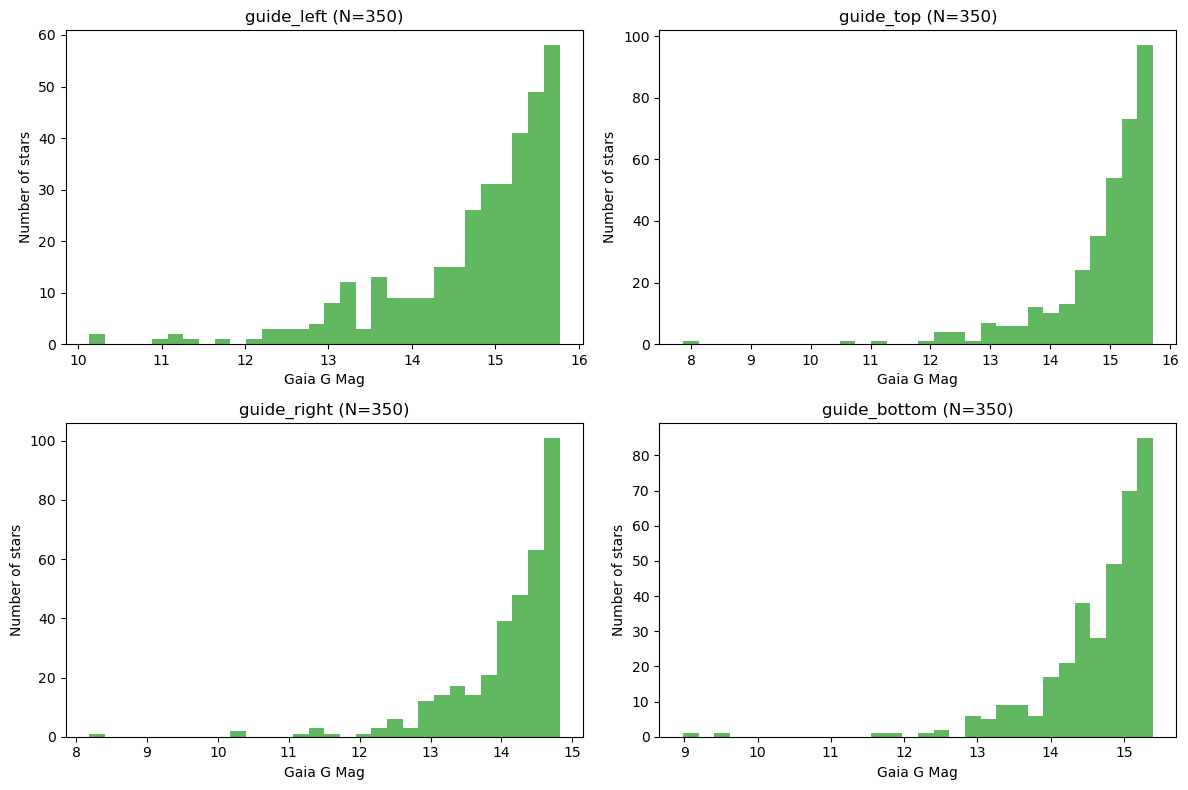

In [1]:
from pathlib import Path
from collections import defaultdict
import shlex

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from astropy.table import Table
    microlens_has_astropy = True
except Exception:
    microlens_has_astropy = False

microlens_base_dir = Path.home() / 'ET7' / 'Results' / 'Microlens' / 'Simulation99m' / 'ly5_500star_jit0p6' / 'microlens_single_01'
microlens_files = sorted(microlens_base_dir.rglob('stars.ecsv'))
print(f'Found {len(microlens_files)} stars.ecsv files under {microlens_base_dir}')

microlens_detector_mags = defaultdict(list)
for stars_file in microlens_files:
    print('Reading', stars_file)
    try:
        if microlens_has_astropy:
            table = Table.read(str(stars_file), format='ascii.ecsv')
            stars_df = table.to_pandas()
        else:
            with open(stars_file, 'r') as fh:
                lines = fh.readlines()
            header_idx = None
            for idx, line in enumerate(lines):
                if not line.strip().startswith('#'):
                    header_idx = idx
                    break
            if header_idx is None:
                print('No header found in', stars_file)
                continue
            header_line = lines[header_idx].strip()
            columns = shlex.split(header_line)
            stars_df = pd.read_csv(stars_file, sep=r'\s+', header=None, names=columns, comment='#', engine='python')
    except Exception as exc:
        print('Failed to read', stars_file, 'error:', exc)
        continue

    if 'Gaia G Mag' not in stars_df.columns:
        print('No Gaia G Mag column in', stars_file)
        continue
    detector_col = 'Detector ID' if 'Detector ID' in stars_df.columns else None
    if detector_col is None:
        detector_col = next((col for col in stars_df.columns if 'detector' in str(col).lower()), None)
    if detector_col is None:
        stars_df['Detector ID'] = 'unknown'
        detector_col = 'Detector ID'

    for detector_id, sub_df in stars_df.groupby(detector_col):
        gmag = pd.to_numeric(sub_df['Gaia G Mag'], errors='coerce').dropna().to_numpy()
        if gmag.size:
            microlens_detector_mags[str(detector_id)].extend(gmag.tolist())

microlens_detector_mags = {
    detector_id: np.asarray(values)
    for detector_id, values in microlens_detector_mags.items()
}

print('Done reading microlens files. Detectors found:', list(microlens_detector_mags.keys()))

total_stars = 0
for detector_id, gmag in microlens_detector_mags.items():
    print(f'{detector_id}: {gmag.size} stars')
    total_stars += gmag.size
print('Total stars:', total_stars)

if not microlens_detector_mags:
    print('No Gaia G magnitude data found in microlens simulation files.')
else:
    plot_order = ['guide_left', 'guide_top', 'guide_right', 'guide_bottom']
    detectors = [det for det in plot_order if det in microlens_detector_mags]
    detectors += [det for det in microlens_detector_mags if det not in detectors]
    n_det = len(detectors)
    cols = 2 if n_det > 1 else 1
    rows = (n_det + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 4 * rows), squeeze=False)
    axes = axes.flatten()

    for idx, detector_id in enumerate(detectors):
        ax = axes[idx]
        gmag = microlens_detector_mags[detector_id]
        ax.hist(gmag, bins=30, color='C2', alpha=0.75)
        ax.set_xlabel('Gaia G Mag')
        ax.set_ylabel('Number of stars')
        ax.set_title(f'{detector_id} (N={gmag.size})')

    for idx in range(n_det, len(axes)):
        axes[idx].axis('off')

    plt.tight_layout()
    microlens_out_png = Path.cwd() / 'microlens_gmag_distribution.png'
    fig.savefig(microlens_out_png, dpi=150)
    print('Saved figure to', microlens_out_png)
    plt.show()